In [ ]:
#Biblioteca para operações numéricas
import numpy as np

#Para visualização
import matplotlib.pyplot as plt

#Para redes neurais
import tensorflow as tf

#Interface de alto nível para construir redes neurais
from tensorflow import keras

#Importando as camadas da rede
from tensorflow.keras.layers import BatchNormalization, Conv2D, Dense, Dropout, Flatten, Input, MaxPooling2D

#Funções utilitárias para trabalhar com imagens
from tensorflow.keras.utils import load_img, img_to_array

from tensorflow.keras.callbacks import EarlyStopping

# Carregar a base de Dados CIFAR-10

In [ ]:
#Carregar a base CIFAR
(X_train, y_train), (X_test, y_test)= keras.datasets.cifar10.load_data()

#Normalizar os valores para um intervalo [0,1]
X_train= X_train.astype("float32") / 255.0
X_test= X_test.astype("float32") / 255.0

#y vem como coluna.
y_train= y_train.flatten()
y_test= y_test.flatten()

class_names= ["avião", "automóvel", "pássaro", "gato", "cervo", "cachorro", "sapo", "cavalo", "navio", "caminhão"]

print(f"Formato de X_train: ", X_train.shape)
print(f"Formato de y_train: ", y_train.shape)
print(f"Formato de X_test: ", X_test.shape)
print(f"Formato de y_test: ", y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 315s 2us/step
Formato de X_train:  (50000, 32, 32, 3)
Formato de y_train:  (50000,)
Formato de X_test:  (10000, 32, 32, 3)
Formato de y_test:  (10000,)


# Plotar algumas Imagens

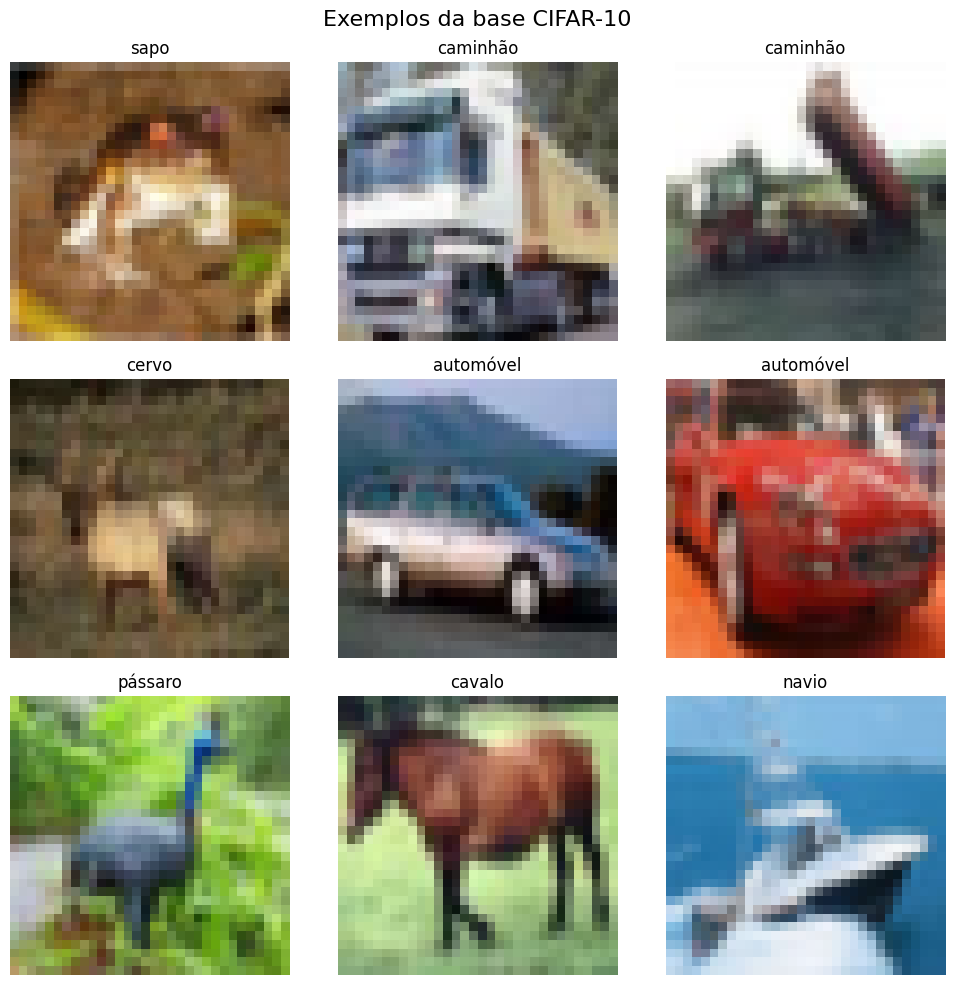

In [ ]:
plt.figure(figsize=(10,10))
for i in range(9):
    plt.subplot(3, 3, i+1)
    plt.imshow(X_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis('off')
plt.suptitle("Exemplos da base CIFAR-10", fontsize=16)
plt.tight_layout()
plt.show()

# Criação do modelo CNN

In [ ]:
model= keras.Sequential()

#Entrada
model.add(Input(shape=(32, 32, 3)))

#Bloco 1
model.add(Conv2D(filters=32, kernel_size=(3, 3), padding='same', activation='relu'))
model.add(BatchNormalization())

model.add(Conv2D(filters=32, kernel_size=(3, 3), padding='same', activation='silu'))
model.add(BatchNormalization())

model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

#Bloco 2
model.add(Conv2D(filters=64, kernel_size=(3, 3), padding='same', activation='relu'))
model.add(BatchNormalization())

model.add(Conv2D(filters=64, kernel_size=(3, 3), padding='same', activation='silu'))
model.add(BatchNormalization())

model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.3))

#Bloco 3
model.add(Conv2D(filters=128, kernel_size=(3, 3), padding='same', activation='relu'))
model.add(BatchNormalization())

model.add(Conv2D(filters=128, kernel_size=(3, 3), padding='same', activation='silu'))
model.add(BatchNormalization())

model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.35))

#CNN
model.add(Flatten())
model.add(Dense(256, activation='relu'))
model.add(BatchNormalization())
model.add(Dropout(0.5))
model.add(Dense(10, activation='softmax'))

#Compilação
model.compile(
    optimizer= 'adam',
    loss= 'sparse_categorical_crossentropy',
    metrics= ['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 816,938 (3.12 MB)

 Trainable params: 815,530 (3.11 MB)

 Non-trainable params: 1,408 (5.50 KB)

# Treinamento

In [ ]:
early_stop= EarlyStopping(
    monitor= 'val_loss',        #Monitora a perda na validação
    patience= 5,                #Espera 5 épocas sem melhora antes de parar
    restore_best_weights= True  #Retorna aos melhores pesos da época ideal
)

history= model.fit(X_train, y_train,
                   epochs=50,
                   batch_size=64,
                   validation_split=0.2,
                   callbacks=[early_stop])

Epoch 1/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 31s 17ms/step - accuracy: 0.4213 - loss: 1.7379 - val_accuracy: 0.5699 - val_loss: 1.2016
Epoch 2/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.5903 - loss: 1.1500 - val_accuracy: 0.6805 - val_loss: 0.8968
Epoch 3/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.6673 - loss: 0.9401 - val_accuracy: 0.7056 - val_loss: 0.8570
Epoch 4/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.7136 - loss: 0.8169 - val_accuracy: 0.7102 - val_loss: 0.8418
Epoch 5/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.7437 - loss: 0.7387 - val_accuracy: 0.7499 - val_loss: 0.7122
Epoch 6/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.7633 - loss: 0.6784 - val_accuracy: 0.7865 - val_loss: 0.6191
Epoch 7/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.7820 - loss: 0.6247 - val_accuracy: 0.7817 - val_loss: 0.6372
Epoch 8/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.7965 - loss: 0.5848 - val_acc

# Plot entre acurácia e do loss

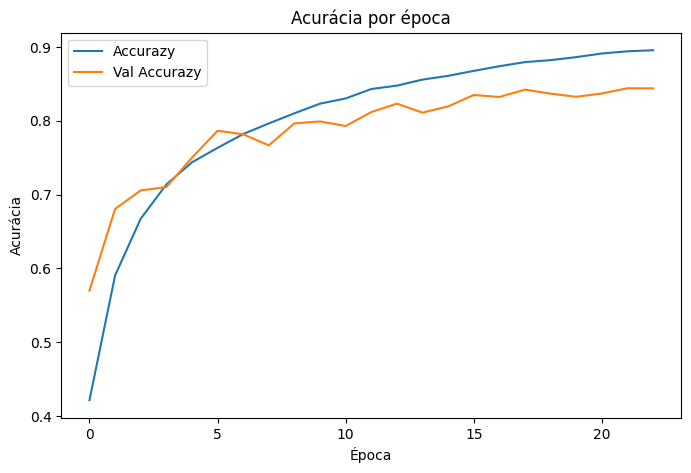

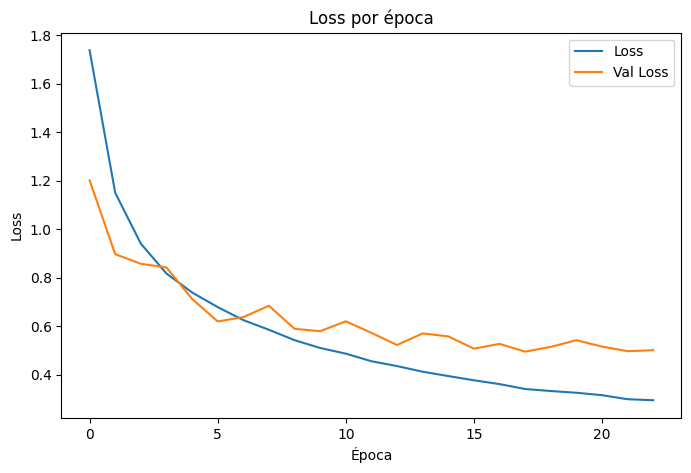

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Accurazy')
plt.plot(history.history['val_accuracy'], label='Val Accurazy')
plt.title("Acurácia por época")
plt.xlabel("Época")
plt.ylabel("Acurácia")
plt.legend()
plt.show()

plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title("Loss por época")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()
plt.show()

# Realizando predições

In [ ]:
test_loss, test_acc= model.evaluate(X_test, y_test)
print(f"Acurácia no teste:{test_acc*100:.2f}%")
print(f"Loss no teste:{test_loss:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8346 - loss: 0.5183
Acurácia no teste:83.46%
Loss no teste:0.5183


# Previsões em Imagens do Teste

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


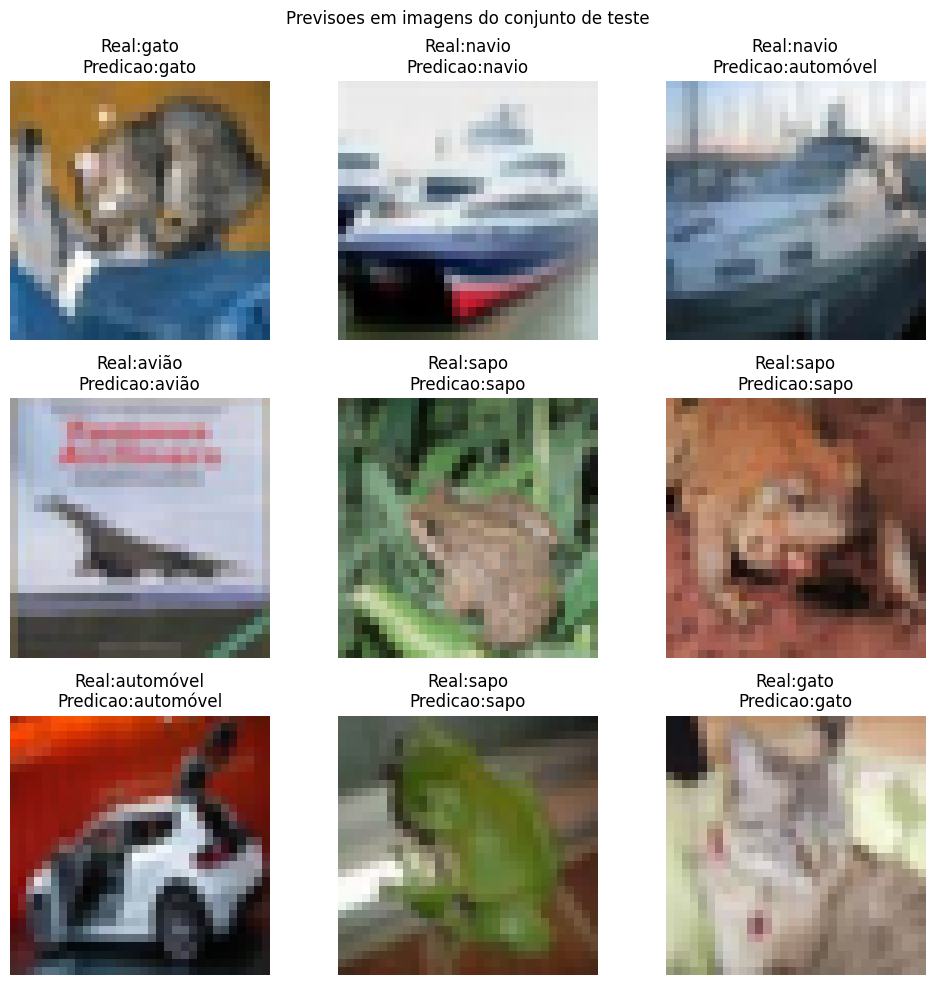

In [ ]:
pred_probs= model.predict(X_test[:9])
pred_labels= np.argmax(pred_probs, axis=1)

plt.figure(figsize=(10,10))
for i in range(9):
    plt.subplot(3, 3, i+1)
    plt.imshow(X_test[i])
    real= class_names[y_test[i]]
    pred= class_names[pred_labels[i]]
    plt.title(f"Real:{real}\nPredicao:{pred}")
    plt.axis('off')
plt.suptitle("Previsoes em imagens do conjunto de teste")
plt.tight_layout()
plt.show()